# Issue #5 · freeze the data protocol before new training

This replaces the historical two-role YOLO11 protocol for the study in parent #4.
Official train supplies a natural 70% training pool / 10% calibration / 20% development
validation allocation. Final test comes from official val after disclosed exclusions.
**No official-val image is opened, decoded, hashed, enhanced or evaluated here.**
Its annotations/metadata and file inventory are split-audit inputs only.

The historical notebooks and `runs/phase2-full` remain evidence, not resumable YOLO26 runs.
Use a fresh root if sources, algorithm, seed or membership changes. The full immutable
manifest stays under gitignored runs; compact membership and audit evidence go in docs.

In [1]:
import gzip
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from IPython.utils.capture import capture_output

from vehicle_detection.common import file_hash, read_json, write_json
from vehicle_detection.data import CLASSES, convert_labels, scan_bdd
from vehicle_detection.offline import export_variant, verify_alignment
from vehicle_detection.protocol import (
    FRACTIONS,
    build_protocol,
    development_records,
    freeze_protocol,
    validate_protocol,
)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
DATA_ROOT = ROOT / "data/bdd100k"
RUN_ROOT = ROOT / "runs/issue5-v1"
REPORT_ROOT = ROOT / "docs/issue5"
SEED, ALLOCATION_ATTEMPTS = 2026, 64
HISTORICAL_SELECTION = ROOT / "runs/phase2-full/selection.json"
RUN_ROOT.mkdir(parents=True, exist_ok=True)
REPORT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})
print("WSL-native dataset:", DATA_ROOT.resolve())
print("Historical selection available:", HISTORICAL_SELECTION.is_file())

WSL-native dataset: /home/truong51972/projects/vehicle-detection/data/bdd100k
Historical selection available: True


## Discover and audit the source populations

The discovery pass inventories paths and streams detection annotations. Missing images
and malformed boxes are counted and excluded explicitly. Vehicle crowd/ignored boxes
and native duplicate boxes are excluded consistently with the existing converters.
Train dimensions come from actual decoded images; val box-size auditing uses the
BDD2018 1280×720 annotation canvas, with image geometry unverified.

Allocation chooses the lowest-drift of 64 seeded group permutations, using class image
presence **and** instances, negative images, sizes, weather, lighting, scene and their
intersections. Targets are natural proportions, not equal class/weather counts.
Explicit video IDs take precedence; filename prefixes are a disclosed fallback.
Exact bytes and equal 64-bit dHash candidates are co-grouped within official train.
Nonzero-distance duplicates and cross-official image-content leakage remain unverified.

In [2]:
records, discovery, sources = scan_bdd(DATA_ROOT, strict=False)
exposure_path = ROOT / "notebooks/test_exposure.json"
exposures = read_json(exposure_path)
excluded_ids = sorted({sample_id for ids in exposures.values() for sample_id in ids})
historical = read_json(HISTORICAL_SELECTION) if HISTORICAL_SELECTION.exists() else None
protocol = build_protocol(
    records,
    sources,
    DATA_ROOT,
    excluded_ids,
    seed=SEED,
    attempts=ALLOCATION_ATTEMPTS,
    historical=historical,
    discovery=discovery,
)
freeze_protocol(RUN_ROOT / "protocol.json", protocol)
assert validate_protocol(read_json(RUN_ROOT / "protocol.json")) == protocol
print("Manifest identity:", protocol["manifest_id"])
display(pd.Series(discovery, name="source discovery"))
display(pd.Series(protocol["label_audit"], name="box audit"))
display(pd.DataFrame(protocol["exclusions"]).groupby("reason").size())
print("Prior exposed IDs:", len(excluded_ids))
display(protocol["group_audit"])
display(protocol.get("historical_diff", "No local historical selection; explicitly unavailable"))

Manifest identity: b308ba62bca6c59f167ae2fa39026a80eece8b542a99d544d7e5b3c079395186


frames:train                                               69863
ignored_nonvehicle_or_polygon_labels                     1345450
frames:val                                                 10000
missing_image_examples                                        []
missing_image_ids                       {'train': [], 'val': []}
Name: source discovery, dtype: object

duplicate_boxes    1
Name: box audit, dtype: int64

reason
group_overlap_official_train      5
group_related_to_exposure       169
prior_exposure                   96
dtype: int64

Prior exposed IDs: 96


{'training_groups': 42109,
 'source_group_kinds': {'bdd_prefix': 79863},
 'duplicate_candidates': {'dhash64': 2, 'sha256': 1}}

{'selection_id': 'd8f6086b184e1460ee375d80246b6c9ca4127339777767bcf32803af30d54d27',
 'old_sizes': {'train': 55890, 'tune': 13973},
 'transitions': {'tune->development_validation': 2774,
  'train->development_validation': 11201,
  'train->calibration': 5638,
  'tune->calibration': 1347,
  'train->training_pool': 39051,
  'tune->training_pool': 9852}}

,images,negative,presence:car,presence:truck,presence:bus,presence:train,presence:motorcycle,presence:bicycle
development_validation,13975,120,13820,3773,1759,17,435,872
calibration,6985,46,6908,1918,936,13,239,425
training_pool,48903,397,48344,13199,6298,75,1610,3046
final_test,9730,88,9612,2621,1212,14,319,566
official_train,69863,563,69072,18890,8993,105,2284,4343
official_val,10000,91,9879,2689,1242,14,334,578


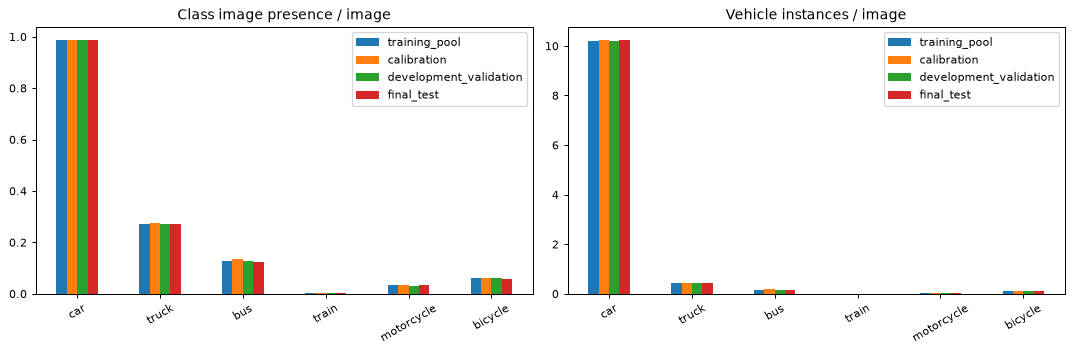

In [3]:
counts = pd.DataFrame(protocol["summaries"]).fillna(0).astype(int)
roles = list(FRACTIONS) + ["final_test"]
display(counts.loc[["images", "negative", *[f"presence:{c}" for c in CLASSES]]].T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, prefix, title in zip(
    axes,
    ["presence", "instances"],
    ["Class image presence / image", "Vehicle instances / image"],
    strict=True,
):
    data = counts.loc[[f"{prefix}:{c}" for c in CLASSES], roles].div(counts.loc["images", roles])
    data.index = CLASSES
    data.plot.bar(ax=ax, title=title, rot=30)
fig.tight_layout()
fig.savefig(REPORT_ROOT / "class_distributions.png")
plt.show()

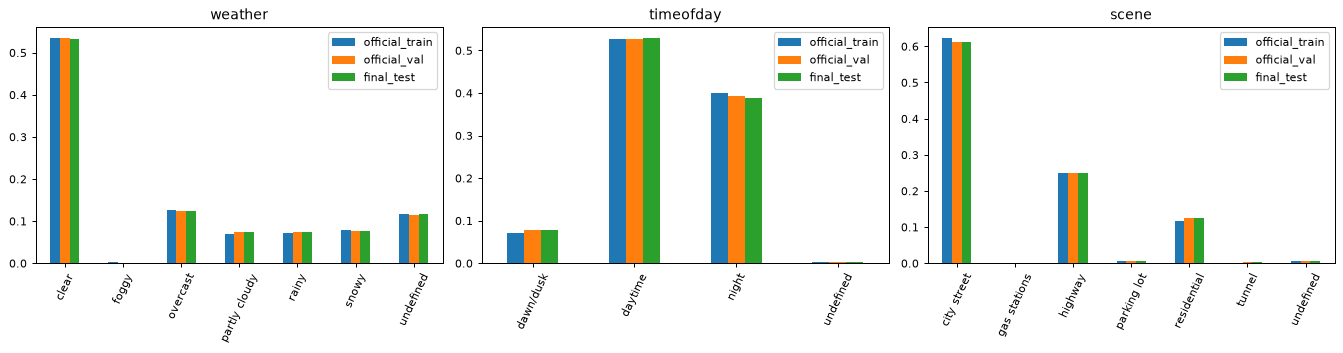

,missing_metadata:scene,missing_metadata:timeofday,missing_metadata:weather
development_validation,79,19,1656
calibration,38,14,821
training_pool,244,104,5642
final_test,51,34,1129
official_train,361,137,8119
official_val,53,35,1157


Official val/final test are descriptive annotation audits, not optimization targets.


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key in zip(axes, ["weather", "timeofday", "scene"], strict=True):
    data = counts.loc[
        [i for i in counts.index if i.startswith(key + ":")],
        ["official_train", "official_val", "final_test"],
    ]
    data.index = data.index.str.split(":", n=1).str[1]
    data.div(counts.loc["images", data.columns]).plot.bar(ax=ax, title=key, rot=65)
fig.tight_layout()
fig.savefig(REPORT_ROOT / "condition_distributions.png")
plt.show()
display(counts.loc[[i for i in counts.index if i.startswith("missing_metadata:")]].T)
print("Official val/final test are descriptive annotation audits, not optimization targets.")

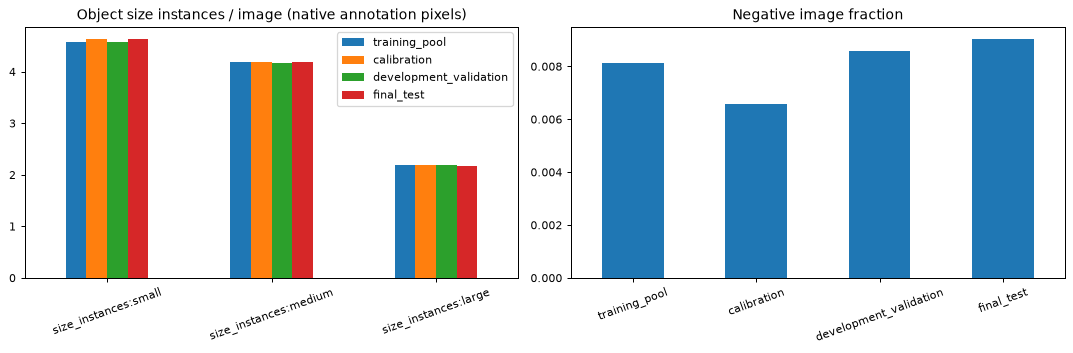

,role,feature,support,expected,delta_per_image,inadequate_support,fallback
172,calibration,intersection:clear|dawn/dusk|gas stations,0,0.299944,-0.000043,True,report parent marginal; no separate inference
337,development_validation,intersection:clear|dawn/dusk|gas stations,0,0.600103,-0.000043,True,report parent marginal; no separate inference
7,training_pool,intersection:clear|dawn/dusk|gas stations,3,2.099953,0.000018,True,report parent marginal; no separate inference
174,calibration,intersection:clear|dawn/dusk|parking lot,4,1.299758,0.000387,True,report parent marginal; no separate inference
339,development_validation,intersection:clear|dawn/dusk|parking lot,2,2.600447,-0.000043,True,report parent marginal; no separate inference
...,...,...,...,...,...,...,...
128,training_pool,intersection:undefined|undefined|residential,1,0.699984,0.000006,True,report parent marginal; no separate inference
295,calibration,intersection:undefined|undefined|undefined,0,1.099795,-0.000157,True,report parent marginal; no separate inference
460,development_validation,intersection:undefined|undefined|undefined,3,2.200378,0.000057,True,report parent marginal; no separate inference
307,calibration,scene:gas stations,2,2.699498,-0.000100,True,report parent marginal; no separate inference


,role,feature,support,expected,delta_per_image,inadequate_support,fallback,abs_drift
315,calibration,size_instances:small,32338,32024.039907,0.044948,False,None,0.044948
167,calibration,instances:car,71516,71307.728698,0.029817,False,None,0.029817
479,development_validation,size_instances:medium,58228,58443.036729,-0.015387,False,None,0.015387
170,calibration,instances:truck,3083,2996.542304,0.012378,False,None,0.012378
320,calibration,timeofday:daytime,3745,3672.116571,0.010434,False,None,0.010434
332,development_validation,instances:car,142541,142666.500866,-0.008980,False,None,0.008980
321,calibration,timeofday:night,2737,2796.579520,-0.008530,False,None,0.008530
165,calibration,instances:bicycle,678,720.865837,-0.006137,False,None,0.006137
352,development_validation,intersection:clear|night|highway,1312,1231.011408,0.005795,False,None,0.005795
150,training_pool,size_instances:small,223923,224204.956844,-0.005766,False,None,0.005766


Support <5: report parent marginal; no separate subgroup inference. No oversampling.
BDD filename prefixes are inferred sequence safeguards, not verified video IDs.
Equal dHash groups candidates only; nonzero-distance near duplicates may remain.
Final-test pixels are unopened; cross-official content duplicates are unverified.
Val geometry uses the BDD2018 1280x720 annotation canvas, not decoded headers.
Rare supports below 5 use parent-marginal reporting; absent classes remain absent.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
size_keys = [f"size_instances:{s}" for s in ["small", "medium", "large"]]
counts.reindex(size_keys, fill_value=0)[roles].div(counts.loc["images", roles]).plot.bar(
    ax=axes[0],
    title="Object size instances / image (native annotation pixels)",
    rot=20,
)
counts.loc[["negative"], roles].div(counts.loc["images", roles]).T.plot.bar(
    ax=axes[1],
    title="Negative image fraction",
    legend=False,
    rot=20,
)
fig.tight_layout()
fig.savefig(REPORT_ROOT / "size_and_background.png")
plt.show()
diagnostics = pd.DataFrame(protocol["diagnostics"])
display(diagnostics.loc[diagnostics.inadequate_support].sort_values(["feature", "role"]))
display(diagnostics.assign(abs_drift=diagnostics.delta_per_image.abs()).nlargest(12, "abs_drift"))
print("Support <5: report parent marginal; no separate subgroup inference. No oversampling.")
print("\n".join(protocol["limitations"]))

## Export only development Raw and commit compact provenance

Reuse the official BDD→Scalabel→COCO→native YOLO converter, including its 0.01-pixel
roundtrip checks. Raw means no enhancement; JPEG quality 95 is the common encoding
contract for Raw/Adaptive later. Train, calibration and final-test export directories
remain empty in this issue. The native YAML `val` key points to development `tune`.
The compressed membership artifact records immutable IDs and group keys, while the
full local manifest also holds paths, source/label hashes, boxes and metadata.

In [6]:
partitions = development_records(protocol, records, DATA_ROOT)
converted = RUN_ROOT / "conversion"
with capture_output() as conversion_log:
    conversion = convert_labels(partitions, converted, convention="continuous")
(RUN_ROOT / "conversion.log").write_text(conversion_log.stdout + conversion_log.stderr)
metadata = export_variant(
    partitions,
    converted,
    RUN_ROOT / "datasets/raw",
    "raw_reencoded",
    {"raw": {}},
    output_format="jpg",
    jpeg_quality=95,
)
assert verify_alignment([RUN_ROOT / "datasets/raw"]) == len(partitions["tune"])
assert not list((RUN_ROOT / "datasets/raw/images/test").iterdir())
print("Deep-verified development Raw images:", len(metadata))
display(conversion)
display(metadata[["preprocess_ms", "preparation_ms"]].agg(["mean", "median", "max"]))

Deep-verified development Raw images: 13975


{'box_convention': 'continuous',
 'classes': ['car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle'],
 'coco_category_ids': [1, 2, 3, 4, 5, 6],
 'geometry_tolerance_pixels': 0.01,
 'versions': {'bdd100k': '1.0.1',
  'scalabel': '0.3.1',
  'ultralytics': '8.4.198'},
 'yolo_category_ids': [0, 1, 2, 3, 4, 5]}

,preprocess_ms,preparation_ms
mean,2.918001,7.694682
median,2.865667,7.643280
max,21.045156,29.073435


In [7]:
membership = pd.DataFrame(
    [
        {"role": role, **{k: row[k] for k in ["id", "group", "source_group"]}}
        for role, rows in protocol["splits"].items()
        for row in rows
    ]
).sort_values(["role", "id"])
member_path = REPORT_ROOT / "split_membership.csv.gz"
compressed = gzip.compress(membership.to_csv(index=False).encode(), mtime=0)
if member_path.exists() and member_path.read_bytes() != compressed:
    raise ValueError("Committed membership changed; version the protocol and review the diff")
member_path.write_bytes(compressed)
summary = {k: v for k, v in protocol.items() if k != "splits"}
summary.update(
    {
        "split_sizes": {role: len(rows) for role, rows in protocol["splits"].items()},
        "membership_sha256": file_hash(member_path),
        "exposure_ledger_sha256": file_hash(exposure_path),
        "local_full_manifest": "runs/issue5-v1/protocol.json",
        "raw_export": read_json(RUN_ROOT / "datasets/raw/export.json"),
        "raw_files_identity": read_json(RUN_ROOT / "datasets/raw/verified.json")["files_identity"],
    }
)
write_json(REPORT_ROOT / "protocol_summary.json", summary)
print("PASS: frozen roles, disclosed exclusions, official conversion, development-only Raw export")
display(pd.Series(summary["split_sizes"], name="frozen image counts"))

PASS: frozen roles, disclosed exclusions, official conversion, development-only Raw export


development_validation    13975
calibration                6985
training_pool             48903
final_test                 9730
Name: frozen image counts, dtype: int64